# First Look at Vulnerability Data

Get up and running with vulnflow in minutes. This notebook pulls the NVD
"Recent" feed (CVEs published in the last ~8 days), enriches it, and
explores basic severity and exploitation-probability distributions.

CacheBuilder is a helper class that wraps the VulnPipeline and provides a simple 
interface for building a cache of vulnerability data. It can be used to build a cache
of recent vulnerabilities, or to build a cache of all vulnerabilities.

In [1]:
from vulnflow.helpers import CacheBuilder

ds = CacheBuilder(recent_only=True).build()

Processing NVD feeds:   0%|          | 0/1 [00:00]

Enriching & transforming:   0%|          | 0/8 [00:00]

In [2]:
df = ds.to_pandas()
print(f"Records Loaded: {len(ds):,}")
print(f"Columns : {len(df.columns)}")
print(f"Date range : {df['nvd_published_at'].min()} .. {df['nvd_published_at'].max()}")
print(f"Avg CVSS : {df['cvss_base_score'].mean():.1f}")
df.head(3)

Records Loaded: 1,352
Columns : 47
Date range : 2026-02-08 05:16:04.353000 .. 2026-02-16 10:16:08.827000
Avg CVSS : 6.8


,id,cve_id,description,nvd_published_at,nvd_modified_at,nvd_status,cvss_version,cvss_base_score,cvss_base_severity,cvss_source,...,cwe_category_name,cwe_abstraction_level,cpe_vendor,cpe_product,cpe_version,cpe_fix_version,capecs,stride_threats,tags,metadata
0,20ad00a3-4446-4b81-95fb-c2721939fd1f,CVE-2026-2134,A security vulnerability has been detected in ...,2026-02-08 05:16:04.353,2026-02-11 18:54:59.870,analyzed,3.1,7.2,HIGH,nvd,...,Improper Neutralization,Class,phpgurukul,hospital_management_system,4.0,NaN,[],[],{},{}
1,bc85a508-f799-463c-9e75-848db514a270,CVE-2026-2135,A vulnerability was detected in UTT HiPER 810 ...,2026-02-08 05:16:07.673,2026-02-13 18:40:09.040,analyzed,3.1,8.8,HIGH,nvd,...,Improper Neutralization,Class,utt,810_firmware,1.7.4-141218,NaN,[],[],{},{}
2,f3a16c3b-0bb4-4772-8b7d-cfa2d19aa692,CVE-2026-2136,A flaw has been found in projectworlds Online ...,2026-02-08 06:16:16.313,2026-02-11 18:54:34.160,analyzed,3.1,9.8,CRITICAL,nvd,...,Improper Neutralization,Class,projectworlds,online_food_ordering_system,1.0,NaN,[],[],{},{}


## Severity Distribution

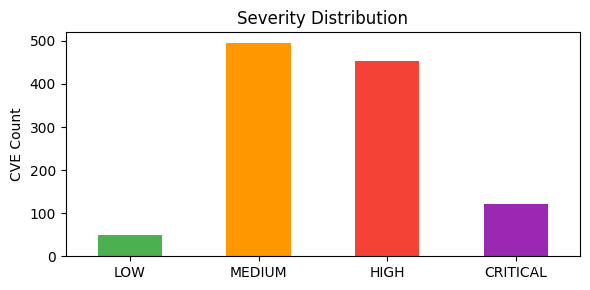

In [3]:
import matplotlib.pyplot as plt

severity_order = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
colors = {"LOW": "#4caf50", "MEDIUM": "#ff9800", "HIGH": "#f44336", "CRITICAL": "#9c27b0"}

counts = (
    df["cvss_base_severity"]
    .value_counts()
    .reindex(severity_order)
    .dropna()
)

fig, ax = plt.subplots(figsize=(6, 3))
counts.plot.bar(ax=ax, color=[colors.get(s, "#999") for s in counts.index])
ax.set_title("Severity Distribution")
ax.set_ylabel("CVE Count")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Most Critical

Top 10 CVEs by base score (>= 9.0).

In [8]:
critical = (
    df.loc[df["cvss_base_score"] >= 9.0]
    .sort_values("cvss_base_score", ascending=False)
    .head(10)
)
critical[["cve_id", "cvss_base_score", "cvss_base_severity", "epss_probability", "cwe_name", "description"]]

,cve_id,cvss_base_score,cvss_base_severity,epss_probability,cwe_name,description
1066,CVE-2025-69770,10.0,CRITICAL,0.00089,Improper Limitation of a Pathname to a Restric...,A zip slip vulnerability in the /DesignTools/S...
1077,CVE-2026-26333,10.0,CRITICAL,0.00097,Missing Authentication for Critical Function,Calero VeraSMART versions prior to 2022 R1 exp...
943,CVE-2026-26216,10.0,CRITICAL,0.00201,Improper Control of Generation of Code ('Code ...,Crawl4AI versions prior to 0.8.0 contain a rem...
274,CVE-2026-25885,10.0,CRITICAL,0.00041,Improper Authorization,PolarLearn is a free and open-source learning ...
715,CVE-2025-64075,10.0,CRITICAL,0.00439,Improper Limitation of a Pathname to a Restric...,A path traversal vulnerability in the check_to...
1057,CVE-2026-26221,10.0,CRITICAL,0.00516,Deserialization of Untrusted Data,Hyland OnBase contains an unauthenticated .NET...
542,CVE-2026-26009,9.9,CRITICAL,0.0026,Improper Neutralization of Special Elements us...,Catalyst is a platform built for enterprise ga...
304,CVE-2026-0488,9.9,CRITICAL,0.00039,Missing Authorization,An authenticated attacker in SAP CRM and SAP S...
169,CVE-2026-1868,9.9,CRITICAL,0.00027,Improper Neutralization of Special Elements Us...,GitLab has remediated a vulnerability in the D...
729,CVE-2025-70085,9.8,CRITICAL,0.00044,Stack-based Buffer Overflow,An issue was discovered in OpenSatKit 2.2.1. T...


## EPSS vs CVSS

Scatter plot with quadrant lines at CVSS = 7 and EPSS = 0.1.
Points in the upper-right quadrant are both high-severity and
likely exploited — prioritize these.

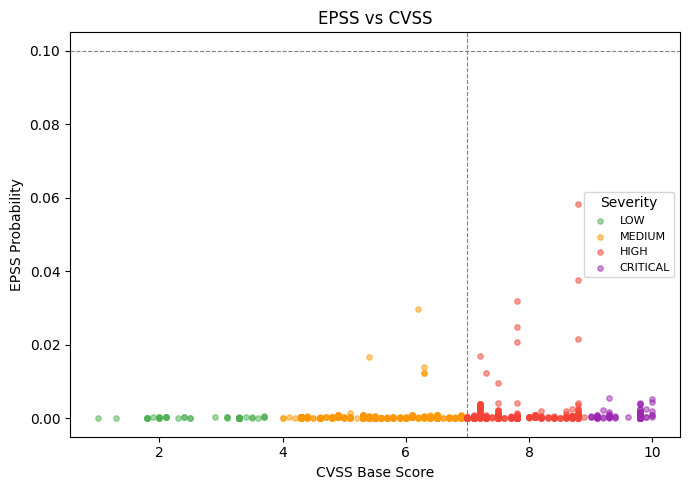

In [9]:
plot_df = df.dropna(subset=["cvss_base_score", "epss_probability"])

fig, ax = plt.subplots(figsize=(7, 5))
for sev in severity_order:
    subset = plot_df[plot_df["cvss_base_severity"] == sev]
    ax.scatter(
        subset["cvss_base_score"],
        subset["epss_probability"],
        label=sev,
        color=colors.get(sev, "#999"),
        alpha=0.5,
        s=15,
    )

ax.axvline(7, color="grey", linestyle="--", linewidth=0.8)
ax.axhline(0.1, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("CVSS Base Score")
ax.set_ylabel("EPSS Probability")
ax.set_title("EPSS vs CVSS")
ax.legend(title="Severity", fontsize=8)
plt.tight_layout()
plt.show()

## Save for Later

Write the dataset to Parquet for fast reloading.

In [10]:
ds.to_parquet("../data/modified_cache.parquet")
print("Saved to ../data/modified_cache.parquet")

Saved to ../data/modified_cache.parquet
